<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/%D0%94%D0%B6%D0%B5%D0%BD%D1%87%D0%B0%D0%BA%D0%BE_%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** ______________________________  
**Група:** ______________________________  
**Дата:** ______________________________

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, losses, metrics
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    TensorBoard,
)
from sklearn.metrics import classification_report, confusion_matrix

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [23]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

print("x_train:", x_train.shape, x_train.dtype)
print("y_train:", y_train.shape)
print("x_test: ", x_test.shape)
print("y_test: ", y_test.shape)
print("Піксели:", x_train.min(), "–", x_train.max())
print("Кількість класів:", len(class_names))

x_train: (60000, 28, 28) uint8
y_train: (60000,)
x_test:  (10000, 28, 28)
y_test:  (10000,)
Піксели: 0 – 255
Кількість класів: 10


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

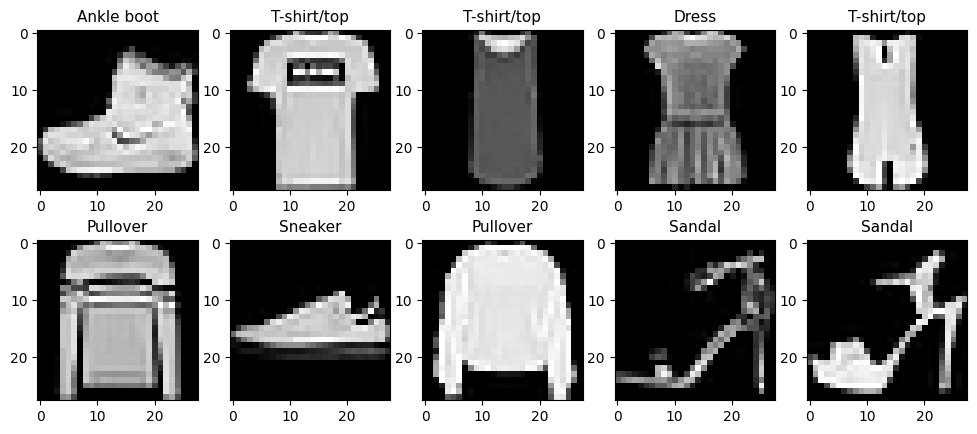

In [24]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
# Виведення перших 10 зображень навчальної вибірки з підписами класів
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=11)
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [25]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
# Завантажуємо дані заново, щоб піксели знову були від 0 до 255
# (це потрібно, бо старі дані вже поділені на 255 кілька разів)
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Нормалізуємо: переводимо в float32 і ділимо на 255
# Тепер значення будуть від 0.0 до 1.0
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Перевіряємо: максимум має бути 1.0
print("Максимум x_train:", x_train.max())
print("Максимум x_test: ", x_test.max())

Максимум x_train: 1.0
Максимум x_test:  1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [26]:
# Створіть і скомпілюйте модель.
# Ваш код:
model=models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax"),   # 10 класів
], name="fashion_mlp")

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",   # цілочисельні мітки
    metrics=["accuracy"],
)

model.summary()

Model: "fashion_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [27]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stop=EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1,
)

reduce_lr=ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1,
)

history=model.fit(
    x_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=2,
)


history_dict = history.history
print("Ключі історії:", list(history_dict.keys()))
print("Виконано епох:", len(history_dict["loss"]))

Epoch 1/50
375/375 - 6s - 17ms/step - accuracy: 0.7673 - loss: 0.6517 - val_accuracy: 0.8413 - val_loss: 0.4371 - learning_rate: 0.0010
Epoch 2/50
375/375 - 3s - 9ms/step - accuracy: 0.8381 - loss: 0.4526 - val_accuracy: 0.8614 - val_loss: 0.3850 - learning_rate: 0.0010
Epoch 3/50
375/375 - 3s - 9ms/step - accuracy: 0.8524 - loss: 0.4105 - val_accuracy: 0.8672 - val_loss: 0.3639 - learning_rate: 0.0010
Epoch 4/50
375/375 - 6s - 16ms/step - accuracy: 0.8607 - loss: 0.3813 - val_accuracy: 0.8728 - val_loss: 0.3492 - learning_rate: 0.0010
Epoch 5/50
375/375 - 4s - 10ms/step - accuracy: 0.8684 - loss: 0.3622 - val_accuracy: 0.8790 - val_loss: 0.3392 - learning_rate: 0.0010
Epoch 6/50
375/375 - 4s - 10ms/step - accuracy: 0.8716 - loss: 0.3530 - val_accuracy: 0.8748 - val_loss: 0.3407 - learning_rate: 0.0010
Epoch 7/50
375/375 - 4s - 11ms/step - accuracy: 0.8765 - loss: 0.3348 - val_accuracy: 0.8798 - val_loss: 0.3272 - learning_rate: 0.0010
Epoch 8/50
375/375 - 5s - 13ms/step - accuracy: 0.


### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [28]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()

print("Кількість шарів:", len(model.layers))

print("Кількість параметрів:", model.count_params())

Model: "fashion_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [30]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)


model.save("/content/drive/MyDrive/fashion_mnist_model.keras")

print("Модель збережено на Google Drive")

Mounted at /content/drive
Модель збережено на Google Drive


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

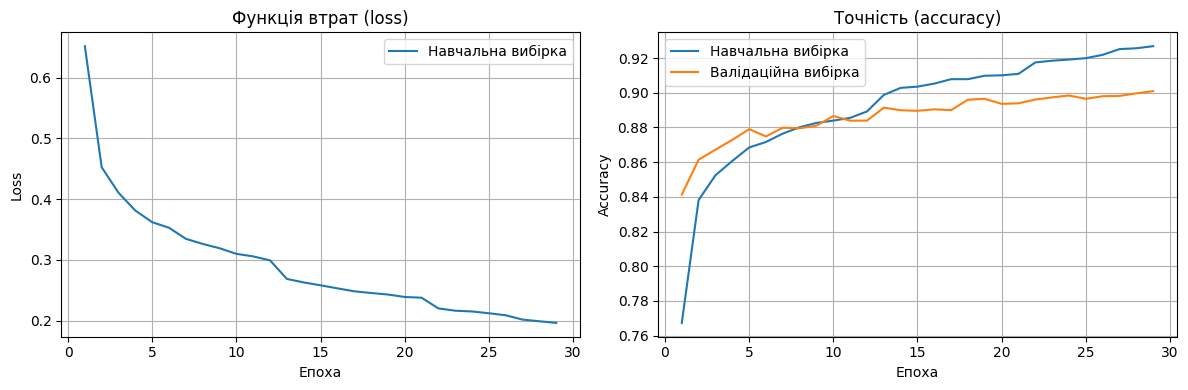

In [31]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
history_dict = history.history

epochs = range(1, len(history_dict["loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history_dict["loss"], label="Навчальна вибірка")


plt.title("Функція втрат (loss)")   # назва графіка
plt.xlabel("Епоха")                 # підпис осі X
plt.ylabel("Loss")                  # підпис осі Y
plt.legend()                        # показуємо легенду
plt.grid(True)                      # сітка для зручності

plt.subplot(1, 2, 2)

plt.plot(epochs, history_dict["accuracy"], label="Навчальна вибірка")

plt.plot(epochs, history_dict["val_accuracy"], label="Валідаційна вибірка")

plt.title("Точність (accuracy)")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [32]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print("Test loss:    ", round(test_loss, 4))
print("Test accuracy:", round(test_acc, 4))


probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(probs, axis=1)



print("\nКласифікаційний звіт:\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

threshold = 0.87

if test_acc >= threshold:
    print(f"Accuracy {test_acc:.4f} >= {threshold}: поріг ДОСЯГНУТО")
else:
    print(f"Accuracy {test_acc:.4f} < {threshold}: поріг НЕ досягнуто")

Test loss:     0.3146
Test accuracy: 0.8932

Класифікаційний звіт:

              precision    recall  f1-score   support

 T-shirt/top     0.8453    0.8580    0.8516      1000
     Trouser     0.9858    0.9730    0.9794      1000
    Pullover     0.8133    0.8060    0.8096      1000
       Dress     0.8791    0.9090    0.8938      1000
        Coat     0.8043    0.8220    0.8131      1000
      Sandal     0.9789    0.9730    0.9759      1000
       Shirt     0.7338    0.7000    0.7165      1000
     Sneaker     0.9500    0.9500    0.9500      1000
         Bag     0.9809    0.9740    0.9774      1000
  Ankle boot     0.9574    0.9670    0.9622      1000

    accuracy                         0.8932     10000
   macro avg     0.8929    0.8932    0.8930     10000
weighted avg     0.8929    0.8932    0.8930     10000

Accuracy 0.8932 >= 0.87: поріг ДОСЯГНУТО


Максимум x_train: 1.5378702e-05
Максимум x_test:  1.5378702e-05
Остання val_accuracy: 0.3866666555404663


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

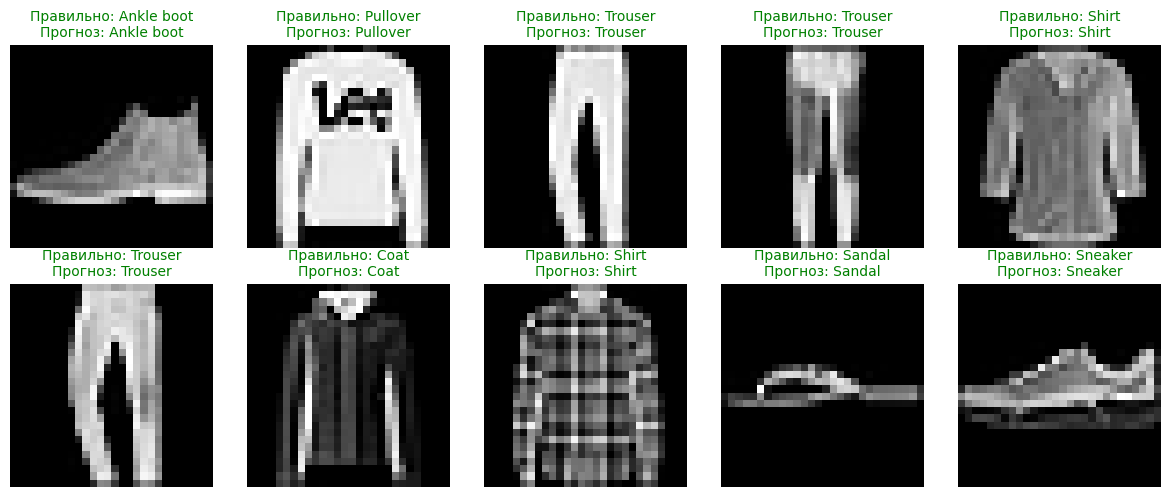

In [33]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(12, 5))


for i in range(10):
    true_label = y_test[i]
    pred_label = y_pred[i]
    if true_label == pred_label:
        color = "green"
    else:
        color = "red"
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Правильно: {class_names[true_label]}\nПрогноз: {class_names[pred_label]}",
              color=color, fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
_..._

Тестова точність 89.3%. Класи з найббільшою кількістю помилок це shirt з 300 помилками. Так отримане значення вище мінімального порогу.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [34]:
!pip install -q keras-tuner

In [37]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split

print("Keras Tuner:", kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [38]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:

(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()


x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0



x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=42,
)


print("Навчальна:   ", x_train.shape, y_train.shape)
print("Валідаційна: ", x_val.shape, y_val.shape)
print("Тестова:     ", x_test.shape, y_test.shape)

print("Максимум x_train:", x_train.max())


assert len(x_train) + len(x_val) == len(x_train_full)
print("Перевірка розмірів пройдена")

Навчальна:    (48000, 28, 28) (48000,)
Валідаційна:  (12000, 28, 28) (12000,)
Тестова:      (10000, 28, 28) (10000,)
Максимум x_train: 1.0
Перевірка розмірів пройдена


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [39]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = models.Sequential()

    model.add(layers.Input(shape=(28, 28)))

    model.add(layers.Flatten())

    num_layers = hp.Int("num_layers", min_value=1, max_value=3)

    dropout_rate = hp.Float("dropout", min_value=0.1, max_value=0.5, step=0.1)

    l2_value = hp.Choice("l2", values=[0.0001, 0.001, 0.01])

    for i in range(num_layers):

        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)

        model.add(layers.Dense(units, activation="relu",
                               kernel_regularizer=l2(l2_value)))

        model.add(layers.Dropout(dropout_rate))


    model.add(layers.Dense(10, activation="softmax"))

    lr = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])


    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [40]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="tuner_results",
    project_name="fashion_mnist_random_search",
    overwrite=True,
    seed=42,
)

tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
dropout (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
l2 (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001, 0.01], 'ordered': True}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [41]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
search_early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
search_reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)

tuner.search(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[search_early_stop, search_reduce_lr],
    verbose=2,
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("\nНайкращі гіперпараметри:")
print("Кількість прихованих шарів:", best_hp.get("num_layers"))
for i in range(best_hp.get("num_layers")):
    print(f"  Нейронів у шарі {i + 1}:", best_hp.get(f"units_{i}"))
print("Dropout:", best_hp.get("dropout"))
print("L2:", best_hp.get("l2"))
print("Learning rate:", best_hp.get("learning_rate"))

best_model = tuner.hypermodel.build(best_hp)
best_model.summary()

final_early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
final_reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)

best_history = best_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=128,
    callbacks=[final_early_stop, final_reduce_lr],
    verbose=2,
)

best_history_dict = best_history.history
print("Виконано епох:", len(best_history_dict["loss"]))
print("Найкраща val_accuracy:", max(best_history_dict["val_accuracy"]))

Trial 3 Complete [00h 01m 31s]
val_accuracy: 0.8169999718666077

Best val_accuracy So Far: 0.878333330154419
Total elapsed time: 00h 04m 33s

Найкращі гіперпараметри:
Кількість прихованих шарів: 2
  Нейронів у шарі 1: 160
  Нейронів у шарі 2: 32
Dropout: 0.1
L2: 0.001
Learning rate: 0.0001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 160)            │       125,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131,082 (512.04 KB)

 Trainable params: 131,082 (512.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
375/375 - 5s - 14ms/step - accuracy: 0.6319 - loss: 1.4469 - val_accuracy: 0.7816 - val_loss: 0.9549 - learning_rate: 1.0000e-04
Epoch 2/50
375/375 - 3s - 7ms/step - accuracy: 0.7658 - loss: 0.9731 - val_accuracy: 0.8169 - val_loss: 0.8202 - learning_rate: 1.0000e-04
Epoch 3/50
375/375 - 3s - 7ms/step - accuracy: 0.7953 - loss: 0.8628 - val_accuracy: 0.8335 - val_loss: 0.7538 - learning_rate: 1.0000e-04
Epoch 4/50
375/375 - 3s - 7ms/step - accuracy: 0.8089 - loss: 0.8046 - val_accuracy: 0.8390 - val_loss: 0.7127 - learning_rate: 1.0000e-04
Epoch 5/50
375/375 - 4s - 10ms/step - accuracy: 0.8205 - loss: 0.7599 - val_accuracy: 0.8458 - val_loss: 0.6808 - learning_rate: 1.0000e-04
Epoch 6/50
375/375 - 4s - 9ms/step - accuracy: 0.8285 - loss: 0.7214 - val_accuracy: 0.8498 - val_loss: 0.6552 - learning_rate: 1.0000e-04
Epoch 7/50
375/375 - 2s - 7ms/step - accuracy: 0.8331 - loss: 0.6945 - val_accuracy: 0.8553 - val_loss: 0.6307 - learning_rate: 1.0000e-04
Epoch 8/50
375/375 - 3s -

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Test loss:     0.4411
Test accuracy: 0.8761
Поріг 0.87 досягнуто: True
Перша модель (ручна): 0.8932


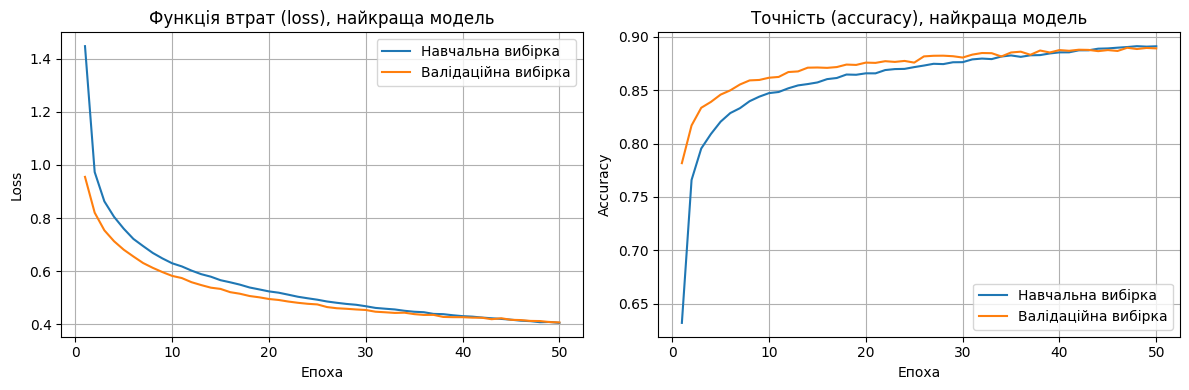

In [42]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
best_test_loss, best_test_acc = best_model.evaluate(x_test, y_test, verbose=0)

print("Test loss:    ", round(best_test_loss, 4))
print("Test accuracy:", round(best_test_acc, 4))

print("Поріг 0.87 досягнуто:", best_test_acc >= 0.87)
print("Перша модель (ручна): 0.8932")

hist = best_history.history

epochs_range = range(1, len(hist["loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, hist["loss"], label="Навчальна вибірка")
plt.plot(epochs_range, hist["val_loss"], label="Валідаційна вибірка")
plt.title("Функція втрат (loss), найкраща модель")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, hist["accuracy"], label="Навчальна вибірка")
plt.plot(epochs_range, hist["val_accuracy"], label="Валідаційна вибірка")
plt.title("Точність (accuracy), найкраща модель")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |2|2|
| Кількість нейронів |256-128|160-32|
| Швидкість навчання |0.001|0.0001|
| Точність на тестовій вибірці (accuracy) |0.8932|0.8761|
| Втрати на тестовій вибірці (loss) |	0.3146|0.4411|
| Кількість епох навчання |24|50|

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
_..._

Так, точність досягнута. Ні оптимізація гіперпараметрів не покращила, навпаки ми отримало 0.87 що менше 0.89.
найкращі гіперпараметри знайшов tuner 2 прихованих шара, 160-32 нейрони, швидкість навчання 0.0001


---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.